In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Carga del dataset

En primer lugar, se carga el conjunto de datos y se comprueba que el separador utilizado es correcto (`;`). Este paso es importante porque una lectura incorrecta del fichero alteraría completamente la estructura del dataset y, por tanto, invalidaría todo el análisis posterior.

In [2]:
from pathlib import Path

# Ruta relativa al repositorio (los notebooks se ejecutan desde notebooks/)
DATA_PATH = Path("..") / "data" / "rendimiento_estudiantes.csv"
# cargar datos
df = pd.read_csv(DATA_PATH, sep=";")

# ver primeras filas
df.head()

,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


In [3]:
# estructura del dataset 
print("Shape:", df.shape)
df.info()

Shape: (4424, 37)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   estado_civil                       4424 non-null   object 
 1   modo_solicitud                     4424 non-null   object 
 2   orden_solicitud                    4424 non-null   int64  
 3   curso                              4424 non-null   object 
 4   asistencia_diurna_vespertina       4424 non-null   object 
 5   cualificacion_previa               4424 non-null   object 
 6   nota_cualificacion_previa          4424 non-null   float64
 7   nacionalidad                       4424 non-null   object 
 8   cualificacion_madre                4424 non-null   object 
 9   cualificacion_padre                4424 non-null   object 
 10  ocupacion_madre                    4424 non-null   object 
 11  ocupacion_padre                    442

In [4]:
# tipos de variables 
df.dtypes.value_counts()

object     18
int64      12
float64     7
Name: count, dtype: int64

In [5]:
cat_cols = df.select_dtypes(include='object').columns
# quitamos los espacios en blanco de stirngs: 
for col in cat_cols:
    df[col] = df[col].str.strip()
num_cols = df.select_dtypes(exclude='object').columns

print("Categóricas:", cat_cols)
print("Numéricas:", num_cols)

Categóricas: Index(['estado_civil', 'modo_solicitud', 'curso',
       'asistencia_diurna_vespertina', 'cualificacion_previa', 'nacionalidad',
       'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre',
       'ocupacion_padre', 'desplazado', 'necesidades_educativas_especiales',
       'deudor', 'matricula_al_dia', 'genero', 'becado', 'internacional',
       'objetivo'],
      dtype='object')
Numéricas: Index(['orden_solicitud', 'nota_cualificacion_previa', 'nota_admision',
       'edad_al_matricularse', 'asignaturas_1sem_convalidadas',
       'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas',
       'asignaturas_1sem_aprobadas', 'nota_media_1sem',
       'asignaturas_1sem_sin_evaluacion', 'asignaturas_2sem_convalidadas',
       'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas',
       'asignaturas_2sem_aprobadas', 'nota_media_2sem',
       'asignaturas_2sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion',
       'pib'],
      dtype='object')


In [6]:
# valores nulos
df.isnull().sum().sort_values(ascending=False)

estado_civil                         0
modo_solicitud                       0
orden_solicitud                      0
curso                                0
asistencia_diurna_vespertina         0
cualificacion_previa                 0
nota_cualificacion_previa            0
nacionalidad                         0
cualificacion_madre                  0
cualificacion_padre                  0
ocupacion_madre                      0
ocupacion_padre                      0
nota_admision                        0
desplazado                           0
necesidades_educativas_especiales    0
deudor                               0
matricula_al_dia                     0
genero                               0
becado                               0
edad_al_matricularse                 0
internacional                        0
asignaturas_1sem_convalidadas        0
asignaturas_1sem_matriculadas        0
asignaturas_1sem_evaluadas           0
asignaturas_1sem_aprobadas           0
nota_media_1sem          

In [7]:
# valores duplicados 
df.duplicated().sum()

np.int64(0)

In [8]:
for col in cat_cols:
    print(col, df[col].nunique())

estado_civil 6
modo_solicitud 18
curso 17
asistencia_diurna_vespertina 2
cualificacion_previa 17
nacionalidad 21
cualificacion_madre 29
cualificacion_padre 34
ocupacion_madre 32
ocupacion_padre 46
desplazado 2
necesidades_educativas_especiales 2
deudor 2
matricula_al_dia 2
genero 2
becado 2
internacional 2
objetivo 3


In [9]:
# variable objetivo
print(df["objetivo"].unique())
print(df["objetivo"].value_counts())
print(df["objetivo"].value_counts(normalize=True))

['abandono' 'graduado' 'matriculado']
objetivo
graduado       2209
abandono       1421
matriculado     794
Name: count, dtype: int64
objetivo
graduado       0.499322
abandono       0.321203
matriculado    0.179476
Name: proportion, dtype: float64


Distribución absoluta:
objetivo
graduado       2209
abandono       1421
matriculado     794
Name: count, dtype: int64

Distribución porcentual:
objetivo
graduado       49.932188
abandono       32.120253
matriculado    17.947559
Name: proportion, dtype: float64


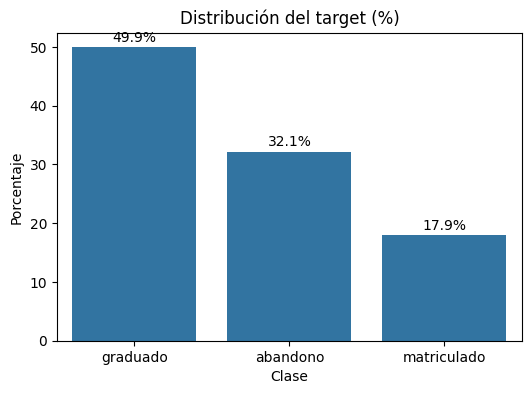

In [10]:
# Distribución absoluta
target_counts = df["objetivo"].value_counts()

# Distribución relativa (porcentajes)
target_pct = df["objetivo"].value_counts(normalize=True) * 100

print("Distribución absoluta:")
print(target_counts)

print("\nDistribución porcentual:")
print(target_pct)

plt.figure(figsize=(6,4))
ax = sns.barplot(
    x=target_pct.index,
    y=target_pct.values
)
# Añadir porcentajes encima de cada barra
for i, v in enumerate(target_pct.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha='center')

plt.title("Distribución del target (%)")
plt.ylabel("Porcentaje")
plt.xlabel("Clase")
plt.show()

### Análisis del desequilibrio de clases

La variable objetivo presenta un claro desequilibrio entre clases:

- Graduado: ~50%
- Abandono: ~32%
- Matriculado: ~18%

Este desbalanceo implica que el modelo podría estar sesgado hacia la clase mayoritaria ("Graduado"), obteniendo buenas métricas globales como accuracy sin capturar correctamente las clases minoritarias.

Por ello, en la fase de modelado será importante utilizar métricas adecuadas para problemas desbalanceados, como el **F1-score macro**, que da el mismo peso a todas las clases independientemente de su frecuencia.

Además, este desequilibrio puede afectar especialmente a la detección de abandono, que es una de las clases más relevantes desde el punto de vista práctico.

In [11]:
cat_cols = df.select_dtypes(include="object").columns.tolist()
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Número de variables categóricas:", len(cat_cols))
print("Número de variables numéricas:", len(num_cols))

print("\nVariables categóricas:")
print(cat_cols)

print("\nVariables numéricas:")
print(num_cols)

Número de variables categóricas: 18
Número de variables numéricas: 19

Variables categóricas:
['estado_civil', 'modo_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'nacionalidad', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'desplazado', 'necesidades_educativas_especiales', 'deudor', 'matricula_al_dia', 'genero', 'becado', 'internacional', 'objetivo']

Variables numéricas:
['orden_solicitud', 'nota_cualificacion_previa', 'nota_admision', 'edad_al_matricularse', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion', 'asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas', 'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion', 'pib']


## 2. Análisis univariante de variables numéricas

A continuación se estudian las principales variables numéricas mediante estadísticos descriptivos e histogramas. El objetivo no es solo conocer sus rangos y escalas, sino también detectar asimetrías, concentraciones de masa en ciertos valores y posibles valores extremos que puedan influir en los modelos.

In [12]:
df.describe()

,orden_solicitud,nota_cualificacion_previa,nota_admision,edad_al_matricularse,asignaturas_1sem_convalidadas,asignaturas_1sem_matriculadas,asignaturas_1sem_evaluadas,asignaturas_1sem_aprobadas,nota_media_1sem,asignaturas_1sem_sin_evaluacion,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.727848,132.613314,126.978119,23.265145,0.709991,6.270570,8.299051,4.706600,10.640822,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,1.313793,13.188332,14.482001,7.587816,2.360507,2.480178,4.179106,3.094238,4.843663,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,0.000000,95.000000,95.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,125.000000,117.900000,19.000000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,133.100000,126.100000,20.000000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,2.000000,140.000000,134.800000,25.000000,0.000000,7.000000,10.000000,6.000000,13.400000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,9.000000,190.000000,190.000000,70.000000,20.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


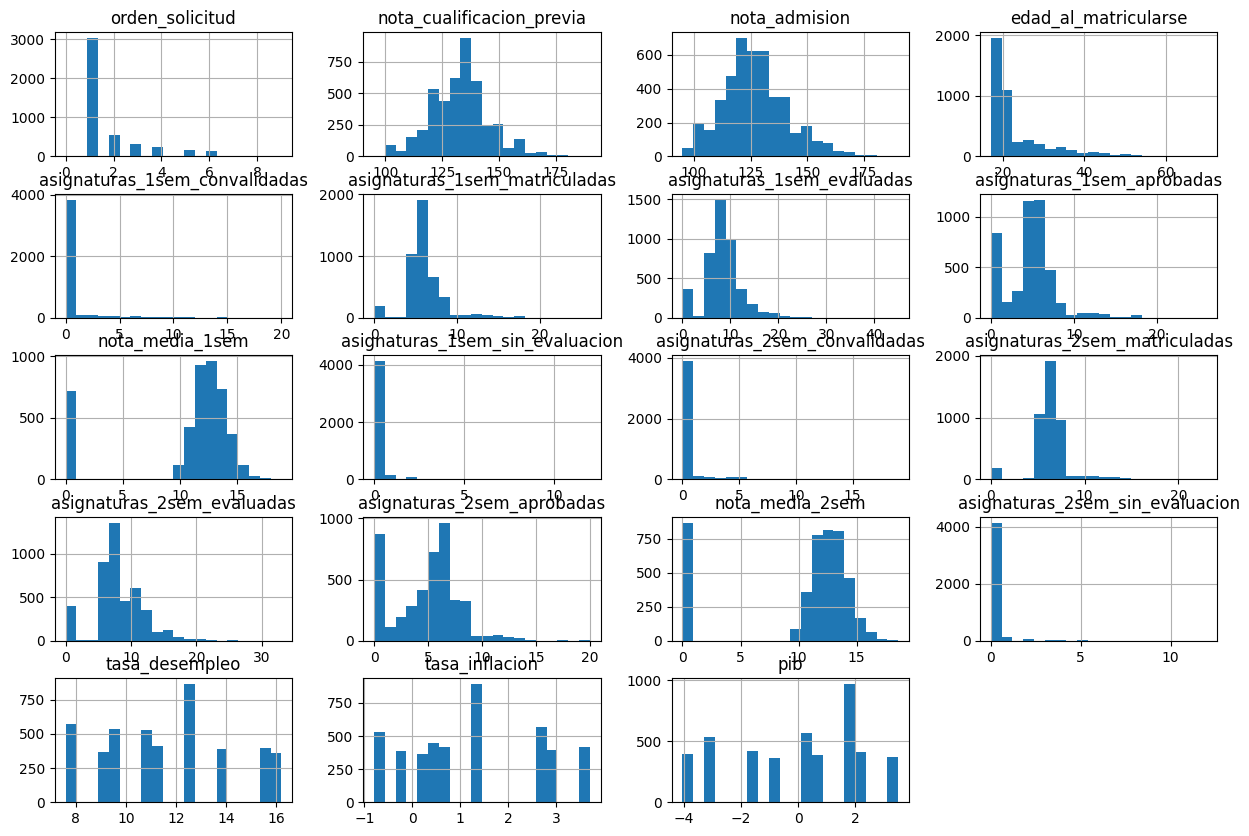

In [13]:
# distribución de variables numéricas: 
df[num_cols].hist(figsize=(15,10), bins=20)
plt.show()


Las distribuciones muestran comportamientos heterogéneos. Algunas variables académicas aparecen concentradas en valores bajos o presentan acumulación en cero, mientras que otras, como las notas, muestran distribuciones más compactas. Esta diferencia sugiere que no todas las variables contienen el mismo tipo de información y anticipa la conveniencia de escalar los datos en los modelos sensibles a la magnitud de las variables.

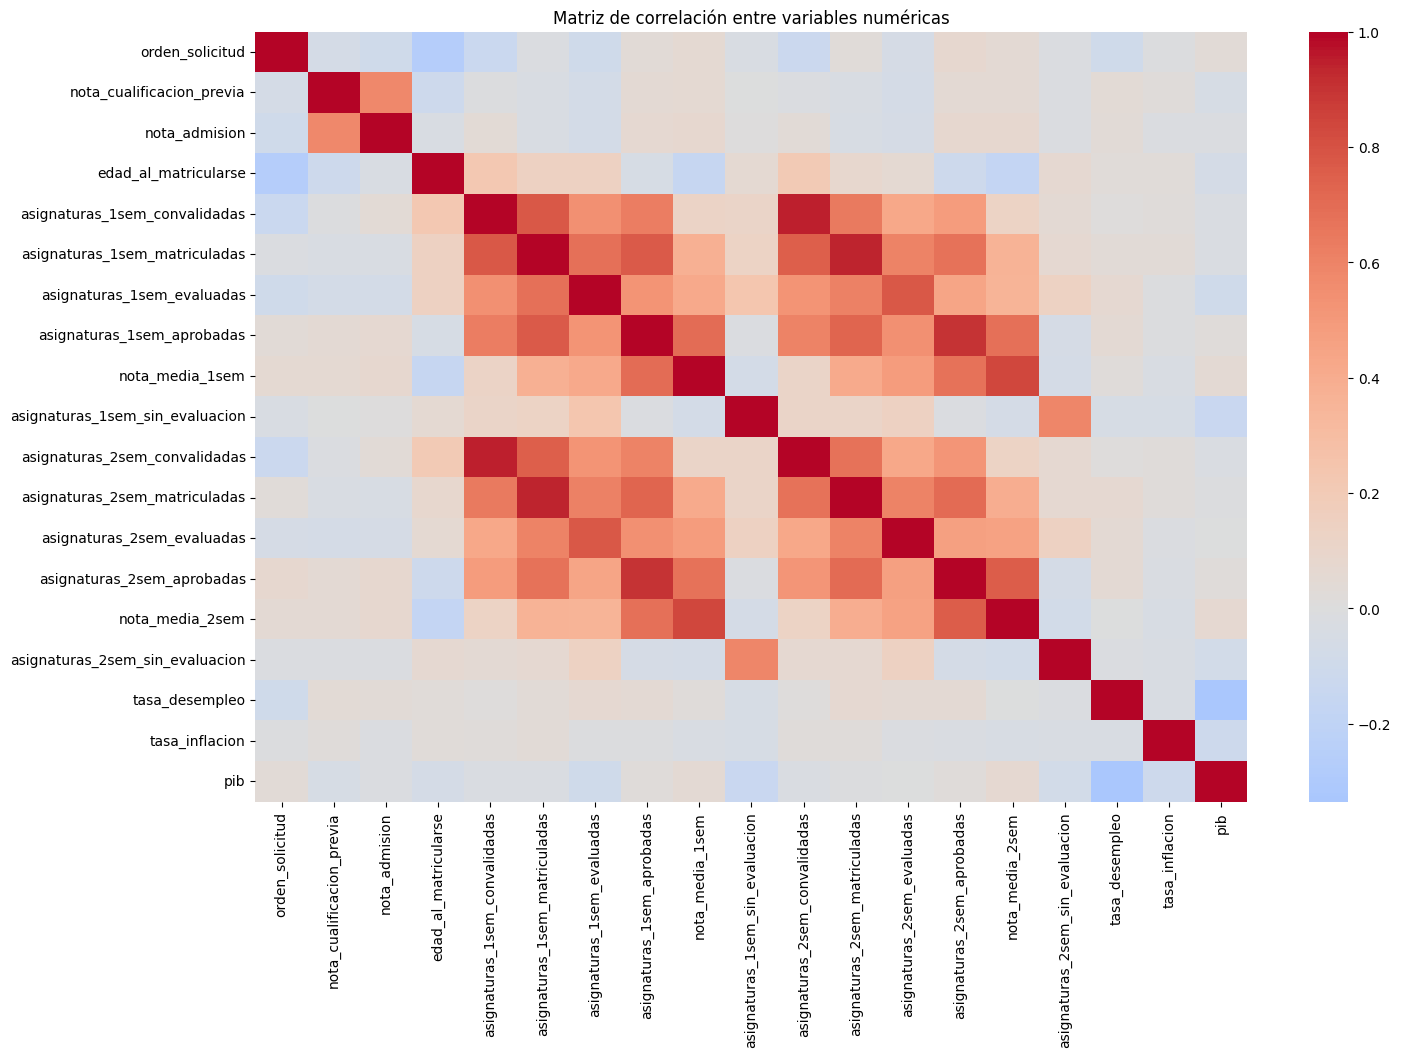

In [14]:
# correlaciones 
corr = df[num_cols].corr(numeric_only=True)

plt.figure(figsize=(16,10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Matriz de correlación entre variables numéricas")
plt.show()

La matriz de correlación permite identificar bloques de variables académicas estrechamente relacionadas, especialmente entre aquellas que describen el rendimiento del primer y segundo semestre. Este resultado era esperable, ya que muchas de estas variables miden dimensiones próximas del progreso académico. Sin embargo, esta alta asociación también obliga a ser prudentes en la tarea de regresión, donde algunas variables del segundo semestre podrían introducir fuga de información respecto a la variable a predecir.

In [15]:
from scipy import stats
z_scores = np.abs(stats.zscore(df[num_cols]))
outliers = (z_scores > 3).sum()
print(outliers)

1072


Se detectan valores extremos en varias variables mediante z-score. Sin embargo, estos valores no se eliminan, ya que corresponden a situaciones reales dentro del contexto del problema (por ejemplo, estudiantes con rendimientos atípicos), y su eliminación podría introducir sesgos en el modelo.

## 3. Relación entre variables relevantes y la variable objetivo

Con el fin de identificar patrones asociados a abandono, permanencia y graduación, se comparan varias variables numéricas clave según la clase objetivo. Esta parte resulta especialmente útil porque permite evaluar si las diferencias entre grupos son lo bastante claras como para esperar capacidad predictiva en los modelos supervisados.

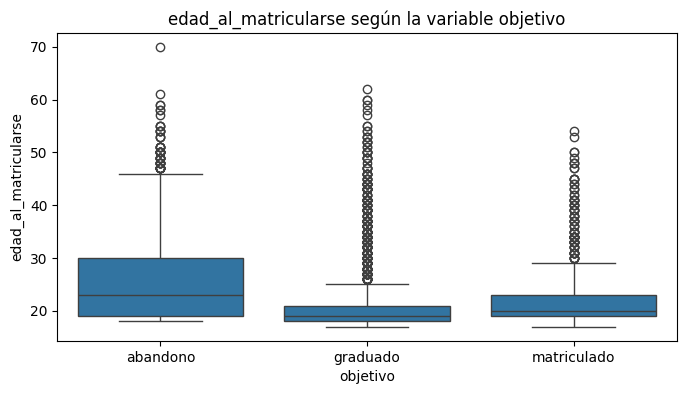

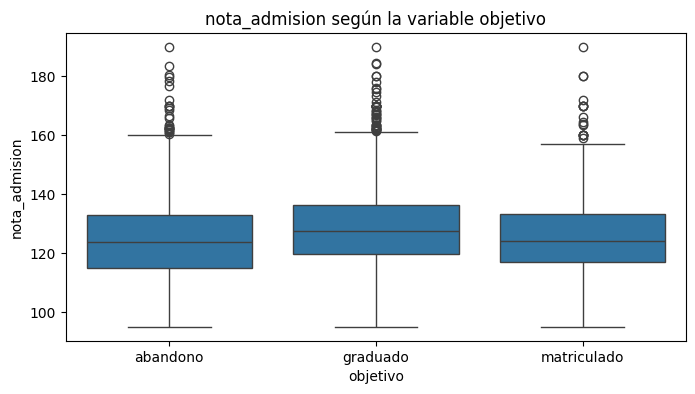

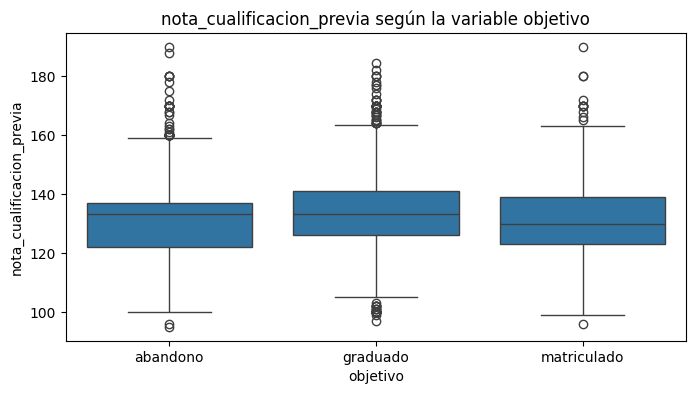

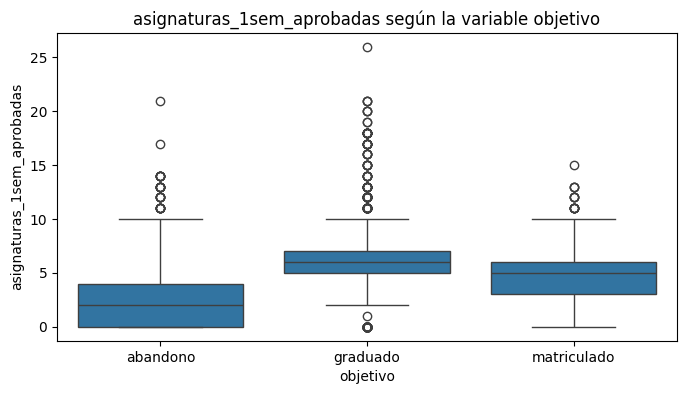

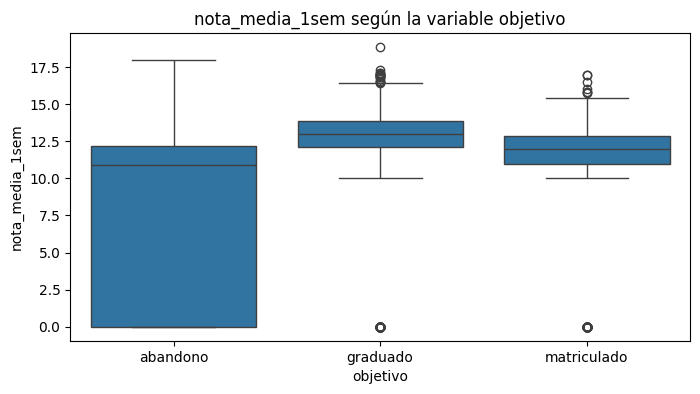

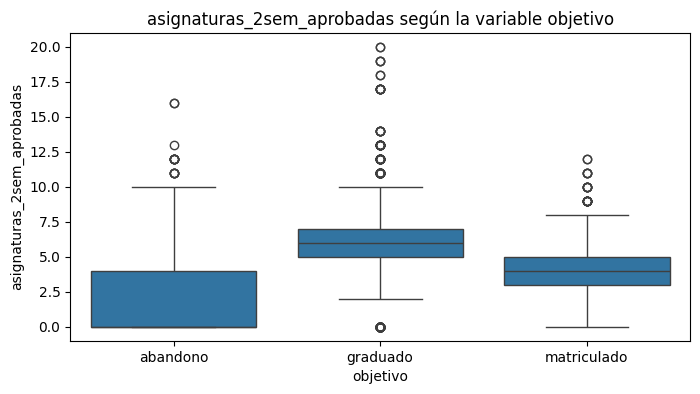

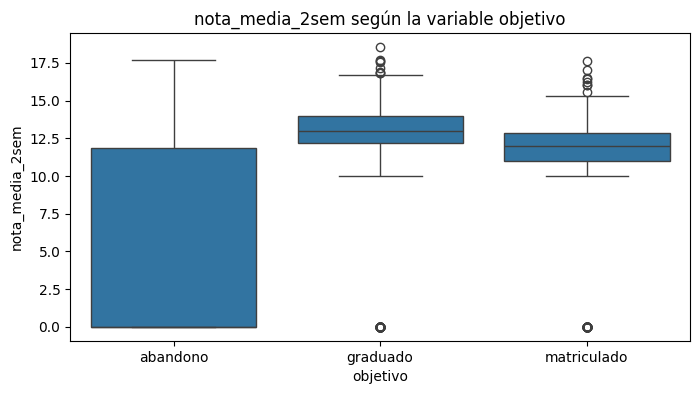

In [16]:
variables_clave = [
    "edad_al_matricularse",
    "nota_admision",
    "nota_cualificacion_previa",
    "asignaturas_1sem_aprobadas",
    "nota_media_1sem",
    "asignaturas_2sem_aprobadas",
    "nota_media_2sem"
]

for col in variables_clave:
    plt.figure(figsize=(8,4))
    sns.boxplot(data=df, x="objetivo", y=col)
    plt.title(f"{col} según la variable objetivo")
    plt.xticks(rotation=0)
    plt.show()

Los gráficos muestran una separación clara entre grupos en las variables ligadas al rendimiento académico. En particular, el número de asignaturas aprobadas y la nota media distinguen de forma visible a los estudiantes graduados de los que abandonan. Esto sugiere que el desempeño académico temprano contiene una señal predictiva fuerte. En cambio, variables como la edad o la nota de admisión aportan información, pero con menor capacidad discriminativa por sí solas.

## 4. Relación entre variables categóricas y la variable objetivo

Además de las variables numéricas, se analizan algunas variables categóricas de interés mediante distribuciones condicionadas a la variable objetivo. Este análisis permite detectar factores administrativos o socioeconómicos que puedan estar asociados con trayectorias académicas distintas.

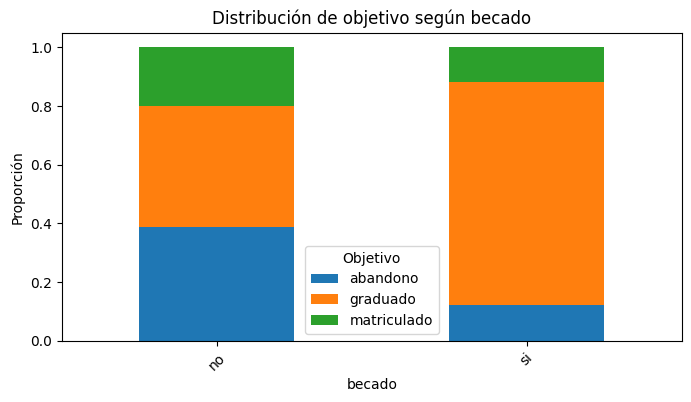

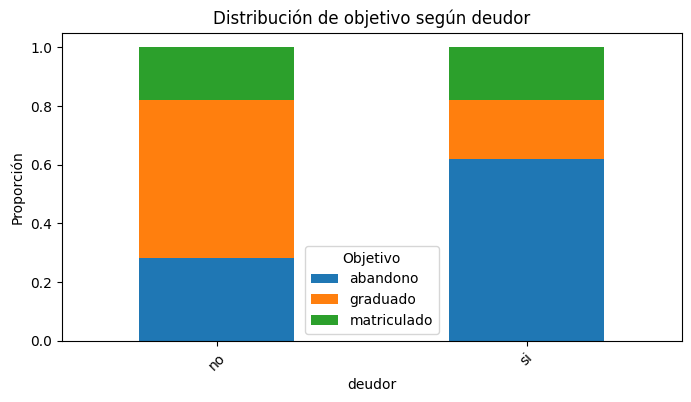

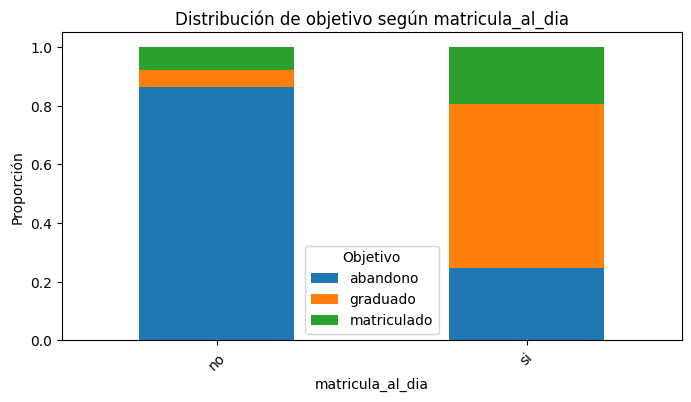

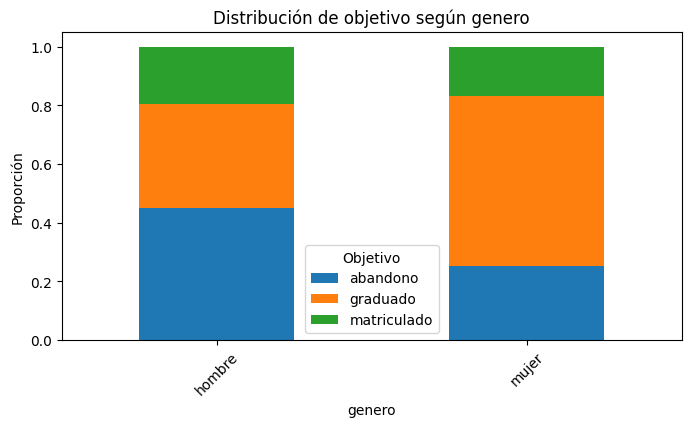

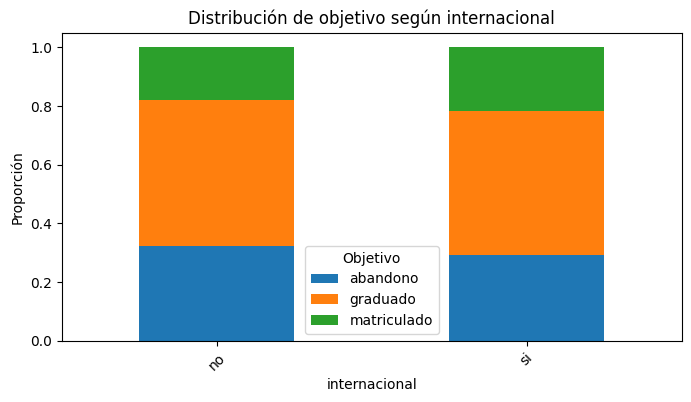

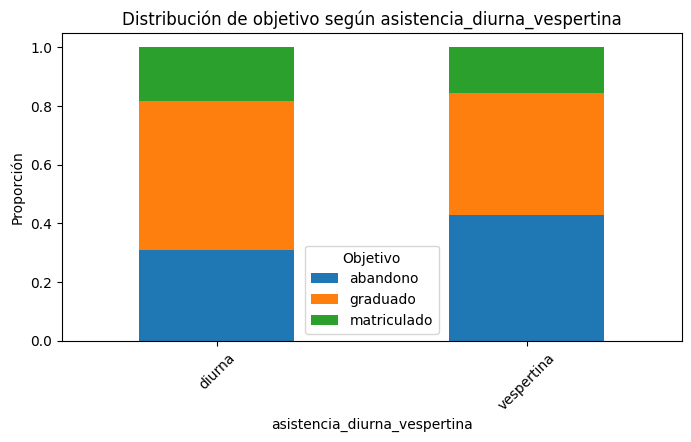

In [17]:
categoricas_clave = [
    "becado",
    "deudor",
    "matricula_al_dia",
    "genero",
    "internacional",
    "asistencia_diurna_vespertina"
]

for col in categoricas_clave:
    tabla = pd.crosstab(df[col], df["objetivo"], normalize="index")
    tabla.plot(kind="bar", stacked=True, figsize=(8,4))
    plt.title(f"Distribución de objetivo según {col}")
    plt.ylabel("Proporción")
    plt.legend(title="Objetivo")
    plt.xticks(rotation=45)
    plt.show()

Se observan diferencias relevantes en algunas variables administrativas y socioeconómicas. En particular, variables como ser becado, ser deudor o tener la matrícula al día parecen asociarse con distribuciones distintas de la variable objetivo. Estas relaciones no deben interpretarse de forma causal, pero sí indican que este tipo de información puede mejorar la capacidad explicativa de los modelos cuando se combina con las variables académicas.

## 5. Implicaciones para la fase de modelado

Las variables del segundo semestre resultan muy informativas, pero no todas podrán utilizarse en todas las tareas. En particular, en la tarea de regresión no será metodológicamente correcto emplear como predictores variables contemporáneas o prácticamente equivalentes a la nota media del segundo semestre, ya que introducirían fuga de información. Por tanto, esta revisión del EDA no solo describe los datos, sino que también permite justificar decisiones posteriores de selección de variables.

In [18]:
columnas_2sem = [col for col in df.columns if "2sem" in col]
print("Variables del segundo semestre:")
print(columnas_2sem)

Variables del segundo semestre:
['asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas', 'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion']


## 6. Conclusiones del EDA

El análisis exploratorio confirma que el dataset está bien estructurado, no presenta valores ausentes y contiene una combinación rica de variables demográficas, administrativas, socioeconómicas y académicas. La mayor capacidad discriminativa parece concentrarse en las variables de rendimiento, especialmente en las relacionadas con asignaturas aprobadas y nota media. Además, se detecta que ciertas variables del segundo semestre, aunque muy informativas, deberán tratarse con cautela en regresión para evitar fuga de información. Esto sugiere que, aunque no es un problema severo, será conveniente considerar métricas adicionales a la accuracy para evaluar los modelos de clasificación. En conjunto, el EDA permite pasar a la fase de modelado con una base metodológica clara.

